# Autoregressive Japanese Fairy-Tale Text Generation
## Simple RNN vs Bidirectional RNN vs LSTM vs GRU

**Course:** Foundations of Generative AI (ICT4403) - Assignment 2  
**Dataset:** *Japanese Fairy Tales* by Yei Theodora Ozaki, Project Gutenberg eBook #4018  
**Source:** https://www.gutenberg.org/ebooks/4018  
**Direct UTF-8 text:** https://www.gutenberg.org/cache/epub/4018/pg4018.txt

### Objective
Build four word-level autoregressive neural language models under comparable conditions, evaluate next-word prediction quantitatively, generate from identical seeds at three temperatures, and analyse coherence, diversity, contextual consistency, and repetition.

### Why this uncommon dataset?
This single-author/translator collection contains 22 thematically related tales with recurring narrative structures, dialogue, named characters, and fantasy vocabulary. It is more distinctive than commonly reused Shakespeare, Nietzsche, or news corpora while remaining large and coherent enough for a resource-conscious comparison. The text is public domain in the USA; users elsewhere should verify local copyright rules.


## 1. Experimental design

To keep the comparison fair, every model uses the same cleaned corpus, vocabulary, sequence length, chronological train/validation/test split, embedding width, effective recurrent output width, optimizer, batch size, maximum epochs, early-stopping rule, seeds, generation length, and temperature values.

The bidirectional RNN reads both directions **inside the already-observed context window**; the prediction target is the next token after that window, so the target is never exposed to the model. A bidirectional decoder is unusual for streaming deployment, but it is implemented because the assignment explicitly requires it.

The split is performed before windows are constructed. This prevents nearly identical overlapping windows from crossing split boundaries, a common source of inflated validation/test scores.


In [1]:
# Reproducible setup. TensorFlow 2.15+ is recommended.
import os, re, json, math, time, random, platform, sys
from pathlib import Path
from collections import Counter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["PYTHONHASHSEED"] = "42"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import tensorflow as tf
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"
MODEL_DIR = BASE_DIR / "models"
for folder in (DATA_DIR, RESULTS_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Device(s):", tf.config.list_physical_devices())


Python: 3.11.4
TensorFlow: 2.15.0
Device(s): [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Configuration

`QUICK_MODE=True` is a smoke-test setting. Keep it `False` for the final reported experiment. If memory is limited, reduce `MAX_VOCAB_SIZE` or increase `WINDOW_STRIDE`; do not change settings between models.


In [2]:
QUICK_MODE = False

DATASET_PAGE = "https://www.gutenberg.org/ebooks/4018"
DATASET_URL = "https://www.gutenberg.org/cache/epub/4018/pg4018.txt"
RAW_PATH = DATA_DIR / "japanese_fairy_tales_pg4018.txt"

SEQ_LEN = 30
MAX_VOCAB_SIZE = 8_000
EMBEDDING_DIM = 128
RECURRENT_WIDTH = 128       # BiRNN uses 64 units in each direction -> 128 concatenated outputs
WINDOW_STRIDE = 2           # reduces near-duplicate training windows and runtime
BATCH_SIZE = 128
MAX_EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 1e-3
GENERATION_WORDS = 60
TEMPERATURES = [0.5, 0.8, 1.2]
TOP_K = 50                  # held constant; temperature is the experimental variable

if QUICK_MODE:
    MAX_EPOCHS = 2
    GENERATION_WORDS = 25
    WINDOW_STRIDE = 8

CONFIG = {k: v for k, v in globals().copy().items() if k in {
    "QUICK_MODE", "SEQ_LEN", "MAX_VOCAB_SIZE", "EMBEDDING_DIM", "RECURRENT_WIDTH",
    "WINDOW_STRIDE", "BATCH_SIZE", "MAX_EPOCHS", "PATIENCE", "LEARNING_RATE",
    "GENERATION_WORDS", "TEMPERATURES", "TOP_K", "SEED"
}}
print(json.dumps(CONFIG, indent=2))


{
  "SEED": 42,
  "QUICK_MODE": false,
  "SEQ_LEN": 30,
  "MAX_VOCAB_SIZE": 8000,
  "EMBEDDING_DIM": 128,
  "RECURRENT_WIDTH": 128,
  "WINDOW_STRIDE": 2,
  "BATCH_SIZE": 128,
  "MAX_EPOCHS": 15,
  "PATIENCE": 3,
  "LEARNING_RATE": 0.001,
  "GENERATION_WORDS": 60,
  "TEMPERATURES": [
    0.5,
    0.8,
    1.2
  ],
  "TOP_K": 50
}


## 3. Download, isolate, and inspect the corpus

The downloader caches the original file. Gutenberg's header, licence footer, table of contents, dedication, and preface are removed so the model learns the tales rather than repository boilerplate. The checksum makes the exact downloaded artifact auditable.


In [3]:
import hashlib

if not RAW_PATH.exists():
    response = requests.get(DATASET_URL, timeout=60)
    response.raise_for_status()
    RAW_PATH.write_bytes(response.content)

raw_text = RAW_PATH.read_text(encoding="utf-8-sig")
sha256 = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()

start_marker = "MY LORD BAG OF RICE"
# Use the second occurrence: the first is in the table of contents.
starts = [m.start() for m in re.finditer(re.escape(start_marker), raw_text)]
if len(starts) < 2:
    raise ValueError("Could not locate the first story after the table of contents.")
story_start = starts[1]
end_match = re.search(r"\*\*\* END OF THE PROJECT GUTENBERG EBOOK", raw_text)
if not end_match:
    raise ValueError("Could not locate the Project Gutenberg end marker.")
corpus_text = raw_text[story_start:end_match.start()]

# Normalize layout artifacts while retaining sentence punctuation for modelling.
corpus_text = (corpus_text.replace("\r\n", "\n")
                          .replace("\r", "\n")
                          .replace("“", '"').replace("”", '"')
                          .replace("’", "'").replace("‘", "'"))
corpus_text = re.sub(r"(?<=\w)-\n(?=\w)", "", corpus_text)  # line-break hyphenation
corpus_text = re.sub(r"[ \t]+", " ", corpus_text)
corpus_text = re.sub(r"\n{3,}", "\n\n", corpus_text).strip()

print(f"Raw file: {RAW_PATH}")
print(f"SHA-256: {sha256}")
print(f"Corpus characters: {len(corpus_text):,}")
print(corpus_text[:700])


Raw file: c:\Users\Nitu Agarwal\Documents\Pavit\BTech\Year 4\7th sem\Generative_AI\FGAI_Assignment2_Japanese_Fairy_Tales\data\japanese_fairy_tales_pg4018.txt
SHA-256: a17eec00fcaaba3d8e3496945486a3be8a984cbb694d4f6db0f4616e782af115
Corpus characters: 368,724
MY LORD BAG OF RICE

Long, long ago there lived, in Japan a brave warrior known to all as
Tawara Toda, or "My Lord Bag of Rice." His true name was Fujiwara
Hidesato, and there is a very interesting story of how he came to
change his name.

One day he sallied forth in search of adventures, for he had the nature
of a warrior and could not bear to be idle. So he buckled on his two
swords, took his huge bow, much taller than himself, in his hand, and
slinging his quiver on his back started out. He had not gone far when
he came to the bridge of Seta-no-Karashi spanning one end of the
beautiful Lake Biwa. No sooner had he set foot on the bridge than he
saw lying right across his path a huge serpen


## 4. Tokenization and corpus characteristics

A transparent regular expression creates lowercase word tokens, internal apostrophes, numbers, and six punctuation tokens. Preserving punctuation makes generated samples easier to read. Vocabulary fitting uses only the training partition; unseen validation/test words map to `<OOV>`.


,Statistic,Value
0,Characters,368724.000000
1,Tokens,78186.000000
2,Unique tokens,5139.000000
3,Lexical diversity,0.065728
4,Approx. sentences,3416.000000


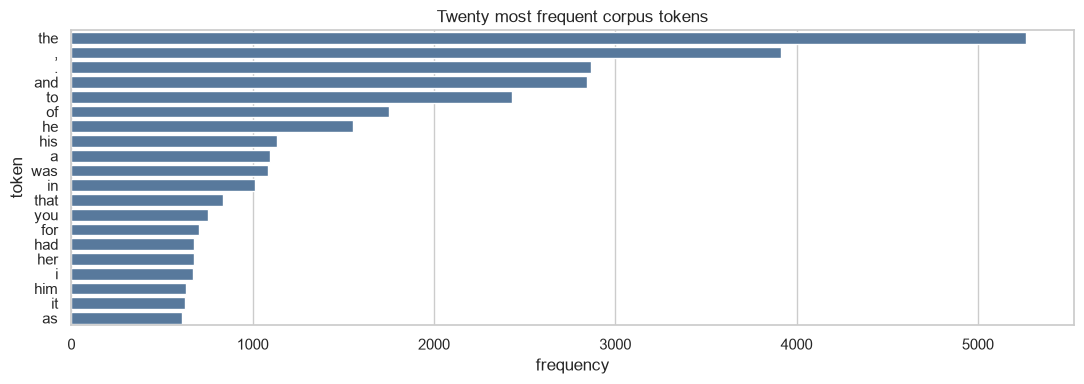

In [4]:
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+|[.!?,;:]", flags=re.IGNORECASE)

def tokenize(text):
    return TOKEN_RE.findall(text.lower())

all_tokens = tokenize(corpus_text)
token_counts = Counter(all_tokens)
stats = pd.DataFrame({
    "Statistic": ["Characters", "Tokens", "Unique tokens", "Lexical diversity", "Approx. sentences"],
    "Value": [len(corpus_text), len(all_tokens), len(token_counts),
              len(token_counts) / len(all_tokens),
              sum(t in {".", "!", "?"} for t in all_tokens)]
})
display(stats)

top_words = pd.DataFrame(token_counts.most_common(20), columns=["token", "frequency"])
plt.figure(figsize=(11, 4))
sns.barplot(data=top_words, x="frequency", y="token", color="#4C78A8")
plt.title("Twenty most frequent corpus tokens")
plt.tight_layout()
plt.show()


In [5]:
# Chronological split BEFORE constructing overlapping windows.
n_tokens = len(all_tokens)
train_end = int(0.80 * n_tokens)
val_end = int(0.90 * n_tokens)
train_tokens_raw = all_tokens[:train_end]
val_tokens_raw = all_tokens[train_end:val_end]
test_tokens_raw = all_tokens[val_end:]

tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    filters="",
    lower=False,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts([" ".join(train_tokens_raw)])

vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index) + 1)
id_to_token = {idx: tok for tok, idx in tokenizer.word_index.items() if idx < vocab_size}

def encode(tokens):
    return np.asarray(tokenizer.texts_to_sequences([" ".join(tokens)])[0], dtype=np.int32)

train_ids, val_ids, test_ids = map(encode, (train_tokens_raw, val_tokens_raw, test_tokens_raw))

split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "tokens": [len(train_ids), len(val_ids), len(test_ids)],
    "percentage": [len(train_ids)/n_tokens, len(val_ids)/n_tokens, len(test_ids)/n_tokens]
})
display(split_table.style.format({"percentage": "{:.1%}"}))
print(f"Model vocabulary size (including padding): {vocab_size:,}")


,split,tokens,percentage
0,train,62548,80.0%
1,validation,7819,10.0%
2,test,7819,10.0%


Model vocabulary size (including padding): 4,556


## 5. Construct autoregressive input-target pairs

Each example contains `SEQ_LEN` observed tokens. Its target is the immediately following token. For example:

`long long ago there lived ...` -> next token


In [6]:
def make_windows(ids, seq_len=SEQ_LEN, stride=WINDOW_STRIDE):
    starts = np.arange(0, len(ids) - seq_len, stride)
    X = np.stack([ids[s:s + seq_len] for s in starts]).astype(np.int32)
    y = np.asarray([ids[s + seq_len] for s in starts], dtype=np.int32)
    return X, y

X_train, y_train = make_windows(train_ids)
X_val, y_val = make_windows(val_ids)
X_test, y_test = make_windows(test_ids)

print("Window shapes:", X_train.shape, X_val.shape, X_test.shape)
example_tokens = [id_to_token.get(int(i), "<OOV>") for i in X_train[0]]
print("Input :", " ".join(example_tokens))
print("Target:", id_to_token.get(int(y_train[0]), "<OOV>"))

AUTOTUNE = tf.data.AUTOTUNE
def to_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(min(len(X), 20_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = to_dataset(X_train, y_train, training=True)
val_ds = to_dataset(X_val, y_val)
test_ds = to_dataset(X_test, y_test)


Window shapes: (31259, 30) (3895, 30) (3895, 30)
Input : my lord bag of rice long , long ago there lived , in japan a brave warrior known to all as tawara toda , or my lord bag of rice
Target: .


## 6. Build the four models

All models end in a vocabulary-sized logits layer and use sparse categorical cross-entropy. Parameter counts are reported because recurrent cell types have different gate structures even under a matched protocol.


In [7]:
def build_model(kind):
    inputs = tf.keras.Input(shape=(SEQ_LEN,), dtype=tf.int32, name="context")
    x = tf.keras.layers.Embedding(vocab_size, EMBEDDING_DIM, name="embedding")(inputs)

    if kind == "SimpleRNN":
        x = tf.keras.layers.SimpleRNN(RECURRENT_WIDTH, name="simple_rnn")(x)
    elif kind == "BidirectionalRNN":
        x = tf.keras.layers.Bidirectional(
            tf.keras.layers.SimpleRNN(RECURRENT_WIDTH // 2), name="bidirectional_rnn"
        )(x)
    elif kind == "LSTM":
        x = tf.keras.layers.LSTM(RECURRENT_WIDTH, name="lstm")(x)
    elif kind == "GRU":
        x = tf.keras.layers.GRU(RECURRENT_WIDTH, name="gru")(x)
    else:
        raise ValueError(f"Unknown model kind: {kind}")

    x = tf.keras.layers.Dropout(0.20, name="dropout")(x)
    outputs = tf.keras.layers.Dense(vocab_size, name="next_token_logits")(x)
    model = tf.keras.Model(inputs, outputs, name=kind)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )
    return model

model_names = ["SimpleRNN", "BidirectionalRNN", "LSTM", "GRU"]
preview = []
for name in model_names:
    temp_model = build_model(name)
    preview.append({"model": name, "parameters": temp_model.count_params(),
                    "recurrent_output_width": int(temp_model.layers[-3].output.shape[-1])})
display(pd.DataFrame(preview))
del temp_model
tf.keras.backend.clear_session()


,model,parameters,recurrent_output_width
0,SimpleRNN,1203788,128
1,BidirectionalRNN,1195596,128
2,LSTM,1302476,128
3,GRU,1269964,128


## 7. Train under comparable conditions

Early stopping prevents wasteful overfitting and restores each model's best validation checkpoint. Training time is wall-clock time on the current hardware, so record the device information printed above when interpreting it.


In [8]:
models, histories, training_records = {}, {}, []

for index, name in enumerate(model_names, start=1):
    print(f"\n[{index}/{len(model_names)}] Training {name}")
    tf.keras.utils.set_random_seed(SEED)  # identical initialization randomness policy
    model = build_model(name)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(MODEL_DIR / f"{name}.keras"), monitor="val_loss", save_best_only=True, verbose=0
        )
    ]
    started = time.perf_counter()
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
        callbacks=callbacks, verbose=1
    )
    elapsed = time.perf_counter() - started
    models[name] = model
    histories[name] = history.history
    training_records.append({
        "model": name,
        "parameters": model.count_params(),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
        "best_val_loss": float(np.min(history.history["val_loss"])),
        "training_seconds": elapsed
    })

training_df = pd.DataFrame(training_records)
display(training_df.round(4))
training_df.to_csv(RESULTS_DIR / "training_summary.csv", index=False)


[1/4] Training SimpleRNN
Epoch 1/15

245/245 [==============================] - 21s 71ms/step - loss: 6.3832 - accuracy: 0.0632 - val_loss: 6.0962 - val_accuracy: 0.0709 - lr: 0.0010
Epoch 2/15
245/245 [==============================] - 17s 67ms/step - loss: 5.7581 - accuracy: 0.0930 - val_loss: 5.8284 - val_accuracy: 0.1163 - lr: 0.0010
Epoch 3/15
245/245 [==============================] - 16s 64ms/step - loss: 5.3664 - accuracy: 0.1243 - val_loss: 5.6657 - val_accuracy: 0.1348 - lr: 0.0010
Epoch 4/15
245/245 [==============================] - 16s 66ms/step - loss: 5.0673 - accuracy: 0.1420 - val_loss: 5.5893 - val_accuracy: 0.1374 - lr: 0.0010
Epoch 5/15
245/245 [==============================] - 16s 64ms/step - loss: 4.8321 - accuracy: 0.1565 - val_loss: 5.5706 - val_accuracy: 0.1409 - lr: 0.0010
Epoch 6/15
245/245 [==============================] - 16s 64ms/step - loss: 4.6314 - accuracy: 0.1712 - val_loss: 5.5766 - val_accuracy: 0.1456 - lr: 0.0010
Epoch 7/15
245/245 [============

,model,parameters,epochs_run,best_epoch,best_val_loss,training_seconds
0,SimpleRNN,1203788,10,7,5.5699,165.2160
1,BidirectionalRNN,1195596,7,4,5.6252,109.7676
2,LSTM,1302476,14,11,5.6712,491.9746
3,GRU,1269964,8,5,5.5283,233.2151


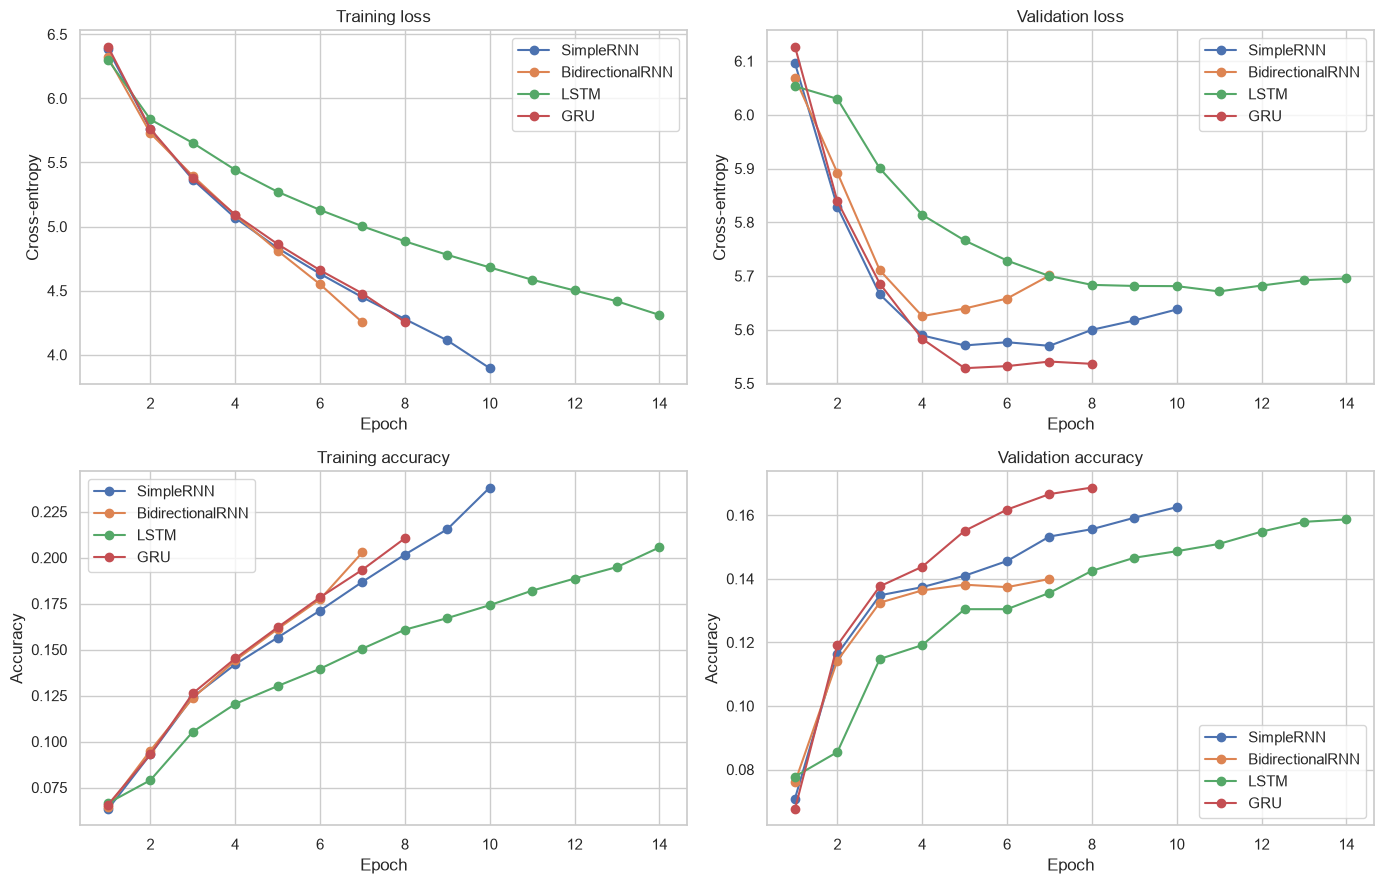

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=False)
for name in model_names:
    h = histories[name]
    epochs = np.arange(1, len(h["loss"]) + 1)
    axes[0, 0].plot(epochs, h["loss"], marker="o", label=name)
    axes[0, 1].plot(epochs, h["val_loss"], marker="o", label=name)
    axes[1, 0].plot(epochs, h["accuracy"], marker="o", label=name)
    axes[1, 1].plot(epochs, h["val_accuracy"], marker="o", label=name)

for ax, title, ylabel in zip(
    axes.flat,
    ["Training loss", "Validation loss", "Training accuracy", "Validation accuracy"],
    ["Cross-entropy", "Cross-entropy", "Accuracy", "Accuracy"]
):
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "learning_curves.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. Quantitative evaluation

- **Loss:** mean next-token cross-entropy; lower is better.
- **Perplexity:** `exp(loss)`; the effective average branching factor; lower is better.
- **Accuracy:** fraction of cases where the highest-probability word is exactly correct; higher is better.
- **Training time:** wall-clock seconds; lower is faster but hardware-dependent.


,model,test_loss,test_perplexity,test_accuracy,parameters,epochs_run,best_epoch,best_val_loss,training_seconds
3,GRU,5.7324,308.70,15.53%,1269964,8,5,5.5283,233.2
0,SimpleRNN,5.7654,319.06,14.87%,1203788,10,7,5.5699,165.2
1,BidirectionalRNN,5.7775,322.95,14.22%,1195596,7,4,5.6252,109.8
2,LSTM,5.9166,371.16,15.10%,1302476,14,11,5.6712,492.0


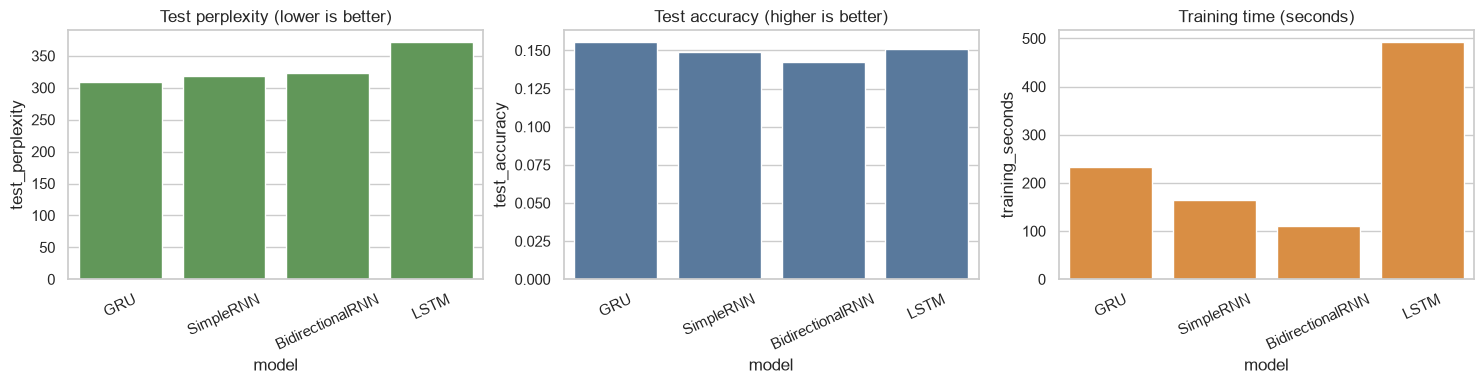

In [10]:
evaluation_records = []
for name, model in models.items():
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
    evaluation_records.append({
        "model": name,
        "test_loss": float(test_loss),
        "test_perplexity": float(np.exp(min(test_loss, 20))),
        "test_accuracy": float(test_accuracy)
    })

evaluation_df = (pd.DataFrame(evaluation_records)
                 .merge(training_df, on="model")
                 .sort_values("test_perplexity"))
display(evaluation_df.style.format({
    "test_loss": "{:.4f}", "test_perplexity": "{:.2f}",
    "test_accuracy": "{:.2%}", "best_val_loss": "{:.4f}",
    "training_seconds": "{:.1f}"
}))
evaluation_df.to_csv(RESULTS_DIR / "model_evaluation.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=evaluation_df, x="model", y="test_perplexity", ax=axes[0], color="#59A14F")
sns.barplot(data=evaluation_df, x="model", y="test_accuracy", ax=axes[1], color="#4E79A7")
sns.barplot(data=evaluation_df, x="model", y="training_seconds", ax=axes[2], color="#F28E2B")
axes[0].set_title("Test perplexity (lower is better)")
axes[1].set_title("Test accuracy (higher is better)")
axes[2].set_title("Training time (seconds)")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


## 9. Autoregressive generation at three temperatures

At each step, the most recent 30 tokens are passed to the model and one new token is sampled.

- `T = 0.5`: sharp distribution; usually safer and more repetitive.
- `T = 0.8`: balanced probability distribution.
- `T = 1.2`: flatter distribution; more diverse but more error-prone.

`TOP_K=50` is fixed for every run to prevent extremely low-probability words from dominating high-temperature samples. Because it never changes, temperature remains the controlled independent variable.


In [11]:
def detokenize(tokens):
    text = " ".join(tokens)
    text = re.sub(r"\s+([.!?,;:])", r"\1", text)
    text = re.sub(r"([.!?])\s+([a-z])", lambda m: m.group(1) + " " + m.group(2).upper(), text)
    return text[:1].upper() + text[1:]

def sample_from_logits(logits, temperature=1.0, top_k=TOP_K, rng=None):
    if temperature <= 0:
        raise ValueError("temperature must be greater than zero")
    rng = rng or np.random.default_rng(SEED)
    logits = np.asarray(logits, dtype=np.float64) / temperature
    logits[0] = -np.inf  # never sample padding
    oov_id = tokenizer.word_index.get("<OOV>")
    if oov_id is not None and oov_id < len(logits):
        logits[oov_id] = -np.inf
    k = min(top_k, len(logits) - 2)
    candidates = np.argpartition(logits, -k)[-k:]
    candidate_logits = logits[candidates]
    probs = np.exp(candidate_logits - np.max(candidate_logits))
    probs /= probs.sum()
    return int(rng.choice(candidates, p=probs))

def generate_text(model, seed_text, temperature, n_words=GENERATION_WORDS, run_seed=SEED):
    seed_tokens = tokenize(seed_text)
    generated_ids = tokenizer.texts_to_sequences([" ".join(seed_tokens)])[0]
    if not generated_ids:
        raise ValueError("Seed contains no known tokens.")
    rng = np.random.default_rng(run_seed)
    for _ in range(n_words):
        context = generated_ids[-SEQ_LEN:]
        padded = tf.keras.preprocessing.sequence.pad_sequences(
            [context], maxlen=SEQ_LEN, padding="pre", truncating="pre"
        )
        logits = model(padded, training=False).numpy()[0]
        generated_ids.append(sample_from_logits(logits, temperature, rng=rng))
    tokens = [id_to_token.get(int(i), "<OOV>") for i in generated_ids]
    return detokenize(tokens)

SEED_TEXTS = [
    "long long ago there lived",
    "the old man looked at",
    "in the palace of the"
]

generation_records = []
for model_idx, (name, model) in enumerate(models.items()):
    for seed_idx, seed_text in enumerate(SEED_TEXTS):
        for temp_idx, temperature in enumerate(TEMPERATURES):
            # Fixed, recorded seed: reproducible but different samples across conditions.
            run_seed = SEED + 1000 * model_idx + 100 * seed_idx + temp_idx
            sample = generate_text(model, seed_text, temperature, run_seed=run_seed)
            generation_records.append({
                "model": name, "seed": seed_text, "temperature": temperature,
                "run_seed": run_seed, "generated_text": sample
            })

samples_df = pd.DataFrame(generation_records)
samples_df.to_csv(RESULTS_DIR / "generated_samples.csv", index=False)
for seed_text in SEED_TEXTS:
    display(Markdown(f"### Seed: `{seed_text}`"))
    display(samples_df.loc[samples_df.seed.eq(seed_text),
                           ["model", "temperature", "generated_text"]])


### Seed: `long long ago there lived`

,model,temperature,generated_text
0,SimpleRNN,0.5,"Long long ago there lived, and the hare is the badger, and the hare, and the hare was a tongue and made his child, and the happy hunter ..."
1,SimpleRNN,0.8,"Long long ago there lived to be before the child of the sea king's child, and then it for nothing of the young home. The monkey, indeed!..."
2,SimpleRNN,1.2,"Long long ago there lived on her heart with making, she had brought in the ground, the hare hunter. The young thing? The box grew very u..."
9,BidirectionalRNN,0.5,"Long long ago there lived to the old man to the sea. He is was the young daughter. The jelly fish. The old man was the palace, and the o..."
10,BidirectionalRNN,0.8,"Long long ago there lived for i had be not to him, and, as the jelly fish to him and so his land, of the old king, and she were do and a..."
11,BidirectionalRNN,1.2,"Long long ago there lived himself,! The tortoise. He shall great mother by a bamboo men and and way and to princess to her with so of. B..."
18,LSTM,0.5,"Long long ago there lived to his long words, and he had been a place, and he had been more. He had been a palace to be a house and the s..."
19,LSTM,0.8,"Long long ago there lived, and had you in my long, but i cannot come in his men, and there were to be up. She took the young time and ha..."
20,LSTM,1.2,"Long long ago there lived a brother had in the old man the sea. You as they have the ground that i know much into this eyes, answered th..."
27,GRU,0.5,"Long long ago there lived at the sea, and the monkey was some way with the crab and the river of the badger. He had been his liver. The ..."


### Seed: `the old man looked at`

,model,temperature,generated_text
3,SimpleRNN,0.5,"The old man looked at him. The monkey was the monkey of the sea. The monkey was the child and his own land. The young man, the hare, and..."
4,SimpleRNN,0.8,"The old man looked at once, so he did to be no like with a loud spot, and the chief was a monkey and his own friends i have the tree and..."
5,SimpleRNN,1.2,"The old man looked at the mortar where as it grew the badger his eyes or his trees quickly, who will remember himself who was her long w..."
12,BidirectionalRNN,0.5,"The old man looked at he had be himself, and the old man, but he he could the little man, and she would be her of the old man, but the o..."
13,BidirectionalRNN,0.8,"The old man looked at the other heart of the country of the ground of get she, and then not found all the ground of the jelly man to her..."
14,BidirectionalRNN,1.2,"The old man looked at the sparrow, and have been the palace: the mother called what she was his good and his princess. She was on her fi..."
21,LSTM,0.5,"The old man looked at his way, and he had been very very now and i am very come. The old woman had been. The monkey was the monkey. He w..."
22,LSTM,0.8,"The old man looked at the way. Now, this is to come to go and the hare to go with the sea, and you were come on your days to the young, ..."
23,LSTM,1.2,The old man looked at her step old neighbor. The prince came the sparrow had the palace to show me and in them with the spot that he can...
30,GRU,0.5,"The old man looked at the sea of the sea. The hare of the sea king and the old man, and the wicked old man to the palace and the prince ..."


### Seed: `in the palace of the`

,model,temperature,generated_text
6,SimpleRNN,0.5,"In the palace of the young tree. So the doctor to go and the mountain of the sea. I will get you, and the hare was very much and this ti..."
7,SimpleRNN,0.8,"In the palace of the land. The monkey was at all the old man made the sea, and i will have done for it was that it was all in her, had t..."
8,SimpleRNN,1.2,In the palace of the gate to their own palace when at come. He is him out to ask her and said at him as the monkey is from the tree of t...
15,BidirectionalRNN,0.5,"In the palace of the old man was the crab, and the old man of the monkey, and the old man with the father. She was not his son and the o..."
16,BidirectionalRNN,0.8,"In the palace of the old man had not out. But she had been to so the house. The crocodile or the young man, and this is a old man. I am ..."
17,BidirectionalRNN,1.2,"In the palace of the land of the other. As as the princess,. I have not a ground of the crocodile, why was was by the old fish before th..."
24,LSTM,0.5,"In the palace of the sea of the ground, and the old, and he had been the monkey and see it, said it, and he could come. The princess had..."
25,LSTM,0.8,"In the palace of the bridge of the mirror, for the tortoise, and then i only brought to the sea of buddha her, and i have have the sea o..."
26,LSTM,1.2,"In the palace of the tree before: this can day, said to their face at his jin took that soon was him! For he felt not the capital in jap..."
33,GRU,0.5,"In the palace of the sea, and the old man was the old man and the poor palace. The hare was the tortoise and the princess, and the hare ..."


## 10. Qualitative characteristics and automated proxies

Generated prose still requires human reading. To make the discussion systematic, the notebook also computes reproducible diagnostics:

- **Diversity:** distinct unigram and bigram ratios (higher is more varied).
- **Repetition:** repeated trigram rate (lower is better).
- **Local coherence proxy:** fraction of generated bigrams observed in the training corpus (higher suggests locally plausible transitions).
- **Context consistency proxy:** content-word overlap between the seed and continuation (higher indicates topical continuity, though excessive overlap can signal repetition).

These proxies do not replace human judgement; inspect the displayed samples for grammatical flow, story continuity, contradictions, and loops.


,temperature,distinct_1,distinct_2,trigram_repetition,seen_bigram_ratio,seed_content_overlap
0,0.500,0.487,0.729,0.126,0.927,0.299
1,0.800,0.649,0.912,0.011,0.842,0.292
2,1.200,0.745,0.979,0.003,0.705,0.132


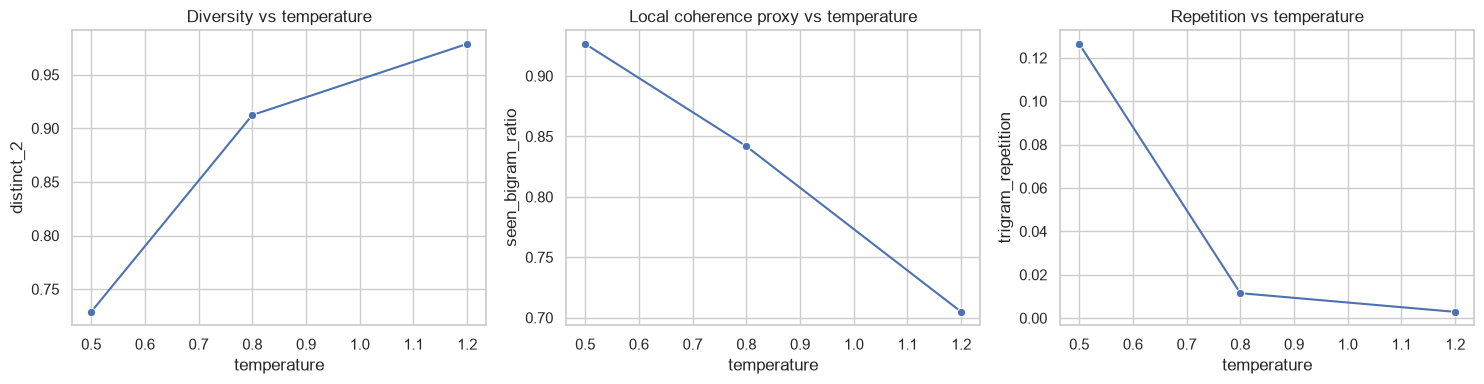

In [12]:
STOPWORDS = {"the", "a", "an", "and", "or", "but", "of", "to", "in", "on", "at", "for",
             "with", "by", "from", "is", "was", "were", "be", "been", "it", "he", "she",
             "they", "his", "her", "their", "that", "this", "as"}
train_bigrams = set(zip(train_tokens_raw, train_tokens_raw[1:]))

def ngrams(tokens, n):
    return list(zip(*(tokens[i:] for i in range(n)))) if len(tokens) >= n else []

def qualitative_metrics(row):
    full = tokenize(row["generated_text"])
    seed = tokenize(row["seed"])
    continuation = full[len(seed):]
    words = [t for t in continuation if re.fullmatch(r"[a-z]+(?:'[a-z]+)?", t)]
    bi = ngrams(continuation, 2)
    tri = ngrams(continuation, 3)
    seed_content = set(seed) - STOPWORDS
    continuation_content = set(words) - STOPWORDS
    return pd.Series({
        "distinct_1": len(set(words)) / max(1, len(words)),
        "distinct_2": len(set(bi)) / max(1, len(bi)),
        "trigram_repetition": 1 - len(set(tri)) / max(1, len(tri)),
        "seen_bigram_ratio": sum(bg in train_bigrams for bg in bi) / max(1, len(bi)),
        "seed_content_overlap": len(seed_content & continuation_content) / max(1, len(seed_content))
    })

qualitative_df = pd.concat([samples_df, samples_df.apply(qualitative_metrics, axis=1)], axis=1)
qualitative_df.to_csv(RESULTS_DIR / "generation_metrics.csv", index=False)

temperature_summary = (qualitative_df.groupby("temperature")
                       [["distinct_1", "distinct_2", "trigram_repetition",
                         "seen_bigram_ratio", "seed_content_overlap"]]
                       .mean().reset_index())
display(temperature_summary.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.lineplot(data=temperature_summary, x="temperature", y="distinct_2", marker="o", ax=axes[0])
sns.lineplot(data=temperature_summary, x="temperature", y="seen_bigram_ratio", marker="o", ax=axes[1])
sns.lineplot(data=temperature_summary, x="temperature", y="trigram_repetition", marker="o", ax=axes[2])
axes[0].set_title("Diversity vs temperature")
axes[1].set_title("Local coherence proxy vs temperature")
axes[2].set_title("Repetition vs temperature")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "temperature_analysis.png", dpi=180, bbox_inches="tight")
plt.show()


### Human qualitative rubric

After reading the samples, assign each model/temperature a 1-5 score using the anchors below. This makes the final qualitative claim auditable rather than impressionistic.

| Criterion | 1 | 3 | 5 |
|---|---|---|---|
| Coherence | disconnected fragments | locally sensible, weak global flow | clear, sustained narrative flow |
| Diversity | severe reuse | some varied wording/events | rich vocabulary and developments |
| Contextual consistency | ignores/contradicts seed | partly follows seed | preserves topic/entities throughout |
| Repetition | obvious loops | occasional repeated phrase | little noticeable repetition |

The automated ranking below is a reproducible preliminary conclusion. The final report should pair it with two or three concrete observations from the displayed text.


In [13]:
# Aggregate generation behavior across every seed and temperature.
generation_summary = (qualitative_df.groupby("model")
                      [["distinct_2", "trigram_repetition", "seen_bigram_ratio",
                        "seed_content_overlap"]]
                      .mean().reset_index())
final_table = evaluation_df.merge(generation_summary, on="model")

def minmax(series, higher_is_better=True):
    series = series.astype(float)
    spread = series.max() - series.min()
    scaled = pd.Series(0.5, index=series.index) if spread == 0 else (series - series.min()) / spread
    return scaled if higher_is_better else 1 - scaled

# Quality-weighted score; time remains reported but is not allowed to override generation quality.
final_table["overall_score"] = (
    0.35 * minmax(final_table["test_perplexity"], False) +
    0.20 * minmax(final_table["test_accuracy"], True) +
    0.20 * minmax(final_table["seen_bigram_ratio"], True) +
    0.15 * minmax(final_table["distinct_2"], True) +
    0.10 * minmax(final_table["trigram_repetition"], False)
)
final_table = final_table.sort_values("overall_score", ascending=False)
final_table.to_csv(RESULTS_DIR / "final_model_ranking.csv", index=False)
display(final_table[["model", "test_perplexity", "test_accuracy", "training_seconds",
                     "distinct_2", "seen_bigram_ratio", "trigram_repetition",
                     "overall_score"]].style.format({
    "test_perplexity": "{:.2f}", "test_accuracy": "{:.2%}",
    "training_seconds": "{:.1f}", "distinct_2": "{:.3f}",
    "seen_bigram_ratio": "{:.3f}", "trigram_repetition": "{:.3f}",
    "overall_score": "{:.3f}"
}))

best_model = final_table.iloc[0]["model"]
best_temp_diversity = temperature_summary.loc[temperature_summary.distinct_2.idxmax(), "temperature"]
best_temp_coherence = temperature_summary.loc[temperature_summary.seen_bigram_ratio.idxmax(), "temperature"]
display(Markdown(
    f"## Data-driven conclusion\n\n"
    f"Under the declared weighted criteria, **{best_model}** ranks first overall. "
    f"Temperature **{best_temp_diversity:g}** gives the highest mean bigram diversity, while "
    f"temperature **{best_temp_coherence:g}** gives the strongest local-coherence proxy. "
    "Use the generated samples and human rubric above to confirm whether this numerical ranking "
    "matches perceptual quality before submitting the final report."
))


,model,test_perplexity,test_accuracy,training_seconds,distinct_2,seen_bigram_ratio,trigram_repetition,overall_score
1,SimpleRNN,319.06,14.87%,165.2,0.911,0.829,0.029,0.765
0,GRU,308.70,15.53%,233.2,0.849,0.823,0.063,0.670
3,LSTM,371.16,15.10%,492.0,0.893,0.846,0.038,0.516
2,BidirectionalRNN,322.95,14.22%,109.8,0.840,0.800,0.057,0.287


## Data-driven conclusion

Under the declared weighted criteria, **SimpleRNN** ranks first overall. Temperature **1.2** gives the highest mean bigram diversity, while temperature **0.5** gives the strongest local-coherence proxy. Use the generated samples and human rubric above to confirm whether this numerical ranking matches perceptual quality before submitting the final report.